In [ ]:
import os
import pandas as pd
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

# Load your dataset if it is not already loaded
df = pd.read_csv("qoute_dataset.csv")

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
df.head()

TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Dataset shape: (3038, 2)
Columns: ['quote', 'Author']


,quote,Author
0,“The world as we have created it is a process ...,Albert Einstein
1,"“It is our choices, Harry, that show what we t...",J.K. Rowling
2,“There are only two ways to live your life. On...,Albert Einstein
3,"“The person, be it gentleman or lady, who has ...",Jane Austen
4,"“Imperfection is beauty, madness is genius and...",Marilyn Monroe


In [ ]:
import re
import unicodedata

def clean_text(text):
    text = unicodedata.normalize("NFKC", str(text))
    text = text.lower()

    # Normalize curly apostrophes
    text = text.replace("’", "'").replace("‘", "'")

    # Put sentence punctuation in separate tokens
    text = re.sub(r"([.!?])", r" \1 ", text)

    # Keep common punctuation and English text
    text = re.sub(r"[^a-z0-9'\s.,!?;:]", " ", text)

    # Normalize whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text


texts = (
    df["quote"]
    .dropna()
    .astype(str)
    .drop_duplicates()
    .apply(clean_text)
)

texts = [text for text in texts if len(text.split()) >= 3]

print("Total quotes:", len(texts))
print("Sample:", texts[0])

Total quotes: 3029
Sample: the world as we have created it is a process of our thinking . it cannot be changed without changing our thinking .


In [ ]:
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer

train_texts, val_texts = train_test_split(
    texts,
    test_size=0.10,
    random_state=42
)

MAX_VOCAB = 9000
MAX_LEN = 30

tokenizer = Tokenizer(
    num_words=MAX_VOCAB,
    oov_token="<OOV>",
    filters="",
    lower=False,
    split=" "
)

tokenizer.fit_on_texts(train_texts)

vocab_size = min(
    MAX_VOCAB,
    len(tokenizer.word_index) + 1
)

print("Training quotes:", len(train_texts))
print("Validation quotes:", len(val_texts))
print("Vocabulary size:", vocab_size)
print("Maximum context length:", MAX_LEN)

Training quotes: 2726
Validation quotes: 303
Vocabulary size: 9000
Maximum context length: 30


In [ ]:
import numpy as np
from tensorflow.keras.preprocessing.sequence import pad_sequences

def make_examples(text_list):
    X_sequences = []
    y = []

    for text in text_list:
        sequence = tokenizer.texts_to_sequences([text])[0]

        for i in range(1, len(sequence)):
            input_sequence = sequence[max(0, i - MAX_LEN):i]
            target_token = sequence[i]

            X_sequences.append(input_sequence)
            y.append(target_token)

    X = pad_sequences(
        X_sequences,
        maxlen=MAX_LEN,
        padding="post",
        truncating="pre"
    )

    return np.asarray(X, dtype=np.int32), np.asarray(y, dtype=np.int32)


X_train, y_train = make_examples(train_texts)
X_val, y_val = make_examples(val_texts)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

X_train: (84948, 30)
y_train: (84948,)
X_val: (8660, 30)
y_val: (8660,)


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, GRU, Dense, Dropout

model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=128,
        mask_zero=True
    ),

    GRU(
        128,
        dropout=0.0,
        recurrent_dropout=0.0
    ),

    Dropout(0.3),

    Dense(
        vocab_size,
        activation="softmax"
    )
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["sparse_categorical_accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-5,
        verbose=1
    )
]

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=128,
    callbacks=callbacks
)

Epoch 1/30
664/664 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - loss: 6.6997 - sparse_categorical_accuracy: 0.0779 - val_loss: 6.0114 - val_sparse_categorical_accuracy: 0.0857 - learning_rate: 0.0010
Epoch 2/30
664/664 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - loss: 6.0331 - sparse_categorical_accuracy: 0.1073 - val_loss: 5.6360 - val_sparse_categorical_accuracy: 0.1186 - learning_rate: 0.0010
Epoch 3/30
664/664 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - loss: 5.6557 - sparse_categorical_accuracy: 0.1331 - val_loss: 5.4692 - val_sparse_categorical_accuracy: 0.1349 - learning_rate: 0.0010
Epoch 4/30
664/664 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - loss: 5.3768 - sparse_categorical_accuracy: 0.1519 - val_loss: 5.3730 - val_sparse_categorical_accuracy: 0.1417 - learning_rate: 0.0010
Epoch 5/30
664/664 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - loss: 5.1300 - sparse_categorical_accuracy: 0.1666 - val_loss: 5.3417 - val_sparse_categorical_accuracy: 0.1439 - learning_rate: 0.0010
Epoch 6/30
664/664 ━━━━━━━━━━━━━━━━━━━━ 7s 10m

271/271 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - loss: 5.3108 - sparse_categorical_accuracy: 0.1507
Validation loss: 5.310826778411865
Validation next-token accuracy: 0.15069283545017242


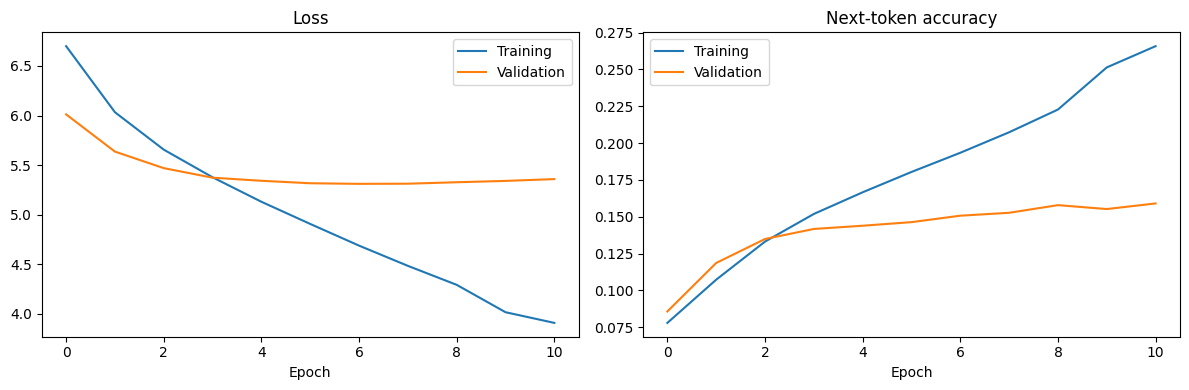

In [ ]:
import matplotlib.pyplot as plt

results = model.evaluate(X_val, y_val, verbose=1)

print("Validation loss:", results[0])
print("Validation next-token accuracy:", results[1])

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(
    history.history["sparse_categorical_accuracy"],
    label="Training"
)
plt.plot(
    history.history["val_sparse_categorical_accuracy"],
    label="Validation"
)
plt.title("Next-token accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
def generate_sentences(
    seed_text,
    target_sentences=4,
    max_new_tokens=60,
    temperature=0.8,
    top_k=8
):
    if not 0 < temperature:
        raise ValueError("temperature must be greater than zero")

    if target_sentences < 1:
        raise ValueError("target_sentences must be at least 1")

    text = clean_text(seed_text)
    generated_tokens = text.split()

    if not generated_tokens:
        return "Please enter some text."

    sentence_count = 0
    oov_index = tokenizer.word_index.get("<OOV>")

    for _ in range(max_new_tokens):
        # Convert the latest context into token IDs
        current_text = " ".join(generated_tokens)
        sequence = tokenizer.texts_to_sequences([current_text])[0]
        sequence = sequence[-MAX_LEN:]

        padded = pad_sequences(
            [sequence],
            maxlen=MAX_LEN,
            padding="post",
            truncating="pre"
        )

        probabilities = model.predict(padded, verbose=0)[0]
        probabilities = probabilities.astype(np.float64)

        # Never generate padding or the OOV placeholder
        probabilities[0] = 0
        if oov_index is not None and oov_index < len(probabilities):
            probabilities[oov_index] = 0

        # Temperature controls how concentrated the distribution is
        probabilities = np.log(
            np.maximum(probabilities, 1e-12)
        ) / temperature

        probabilities = np.exp(
            probabilities - np.max(probabilities)
        )

        # Keep only the top-k candidates
        k = min(top_k, len(probabilities))
        candidate_indices = np.argpartition(
            probabilities, -k
        )[-k:]

        filtered = np.zeros_like(probabilities)
        filtered[candidate_indices] = probabilities[candidate_indices]

        total = filtered.sum()
        if total == 0 or not np.isfinite(total):
            break

        filtered /= total

        next_index = int(
            np.random.choice(len(filtered), p=filtered)
        )

        next_token = tokenizer.index_word.get(next_index)

        if not next_token or next_token == "<OOV>":
            break

        generated_tokens.append(next_token)

        if next_token in {".", "!", "?"}:
            sentence_count += 1

            if sentence_count >= target_sentences:
                break

    # Reconstruct readable text
    output = " ".join(generated_tokens)
    output = re.sub(r"\s+([.,!?;:])", r"\1", output)
    output = re.sub(r"\s+", " ", output).strip()

    # Capitalize the beginning and after sentence-ending punctuation
    output = output.capitalize()
    output = re.sub(
        r"([.!?]\s+)([a-z])",
        lambda match: match.group(1) + match.group(2).upper(),
        output
    )

    if output and output[-1] not in ".!?":
        output += "."

    return output

In [ ]:
print(generate_sentences("the world"))
print()
print(generate_sentences("my name is"))
print()
print(generate_sentences("success comes from"))

The world is the beginning of the world is not in the sea of the middle of our mind. The right is to see the universe is a place...

My name is not in the road is a book. I shall be happy. If i don't know it is a lot of a way for your heart. And then you don't have not a lot of your own own.

Success comes from my family of the same world and the best thing you can make your life is always in the same thing for a person is a book of your life is the same time is to make a person who are a person who was a lot of our own own life. I would be a girl who will.


In [ ]:
print(generate_sentences("success comes from"))
print(generate_sentences("life is full of"))
print(generate_sentences("never give up because"))

Success comes from the world. We do that we are not to be as they are not to be able to be a good thing that is a man of the world. And the best thing that you think you have to do. It's just to find us with you, but the same thing to live.
Life is full of your mind. I have never know it. I have never been to be happy. I would not know you will have you.
Never give up because that we will love you. But you are a person...


In [ ]:

for name in ["model", "tokenizer", "MAX_LEN"]:
    print(f"{name} exists:", name in globals())

if "model" in globals():
    model.summary()


model exists: True
tokenizer exists: True
MAX_LEN exists: True


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 30, 128)        │     1,152,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 128)            │        99,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 9000)           │     1,161,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,236,218 (27.60 MB)

 Trainable params: 2,412,072 (9.20 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 4,824,146 (18.40 MB)

In [ ]:

import pickle

# 1. Save the trained GRU model
model.save("/content/sentence_generator_gru.keras")

# 2. Save the tokenizer
with open("/content/tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

# 3. Save the maximum sequence length
with open("/content/max_len.pkl", "wb") as f:
    pickle.dump(MAX_LEN, f)

print("All three files saved successfully!")


All three files saved successfully!


In [ ]:

import os

files_to_check = [
    "/content/sentence_generator_gru.keras",
    "/content/tokenizer.pkl",
    "/content/max_len.pkl"
]

for path in files_to_check:
    if os.path.exists(path):
        print(f"Saved: {os.path.basename(path)}")
        print(f"Size: {os.path.getsize(path) / (1024 * 1024):.2f} MB")
    else:
        print(f"Missing: {path}")


Saved: sentence_generator_gru.keras
Size: 27.63 MB
Saved: tokenizer.pkl
Size: 0.34 MB
Saved: max_len.pkl
Size: 0.00 MB


In [ ]:

from google.colab import files

files.download("/content/sentence_generator_gru.keras")
files.download("/content/tokenizer.pkl")
files.download("/content/max_len.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>